# Quantum layer spectral bandwidth: does more encoding layers buy more spectrum?

This notebook isolates a few questions out of the broader QPINN-vs-classical-PINN
comparison, all centred on the MerLin quantum layer's own frequency content:

1. **Setup & sanity check** — confirm the feature→circuit-slot mapping this
   notebook assumes actually holds for your build of MerLin/Perceval.
2. **Proof of the analytic bound** — a full derivation of why the quantum
   layer's accessible spectrum is bounded by `L * n_photons`, and why the
   *probability* spectrum (not the raw amplitude) is the one that matters.
3. **Analytic bound vs. architecture** — at initialization (no training),
   does the quantum layer's spectrum widen linearly with `L` the way the
   proof predicts?
4. **Analytic bound vs. the learned function** — after training on a
   high-frequency PDE, how much of that allowed spectrum does the trained
   circuit use?
5. **Physical solution spectrum vs. the analytical solution, across L** —
   the theta-space picture in 3-4 is one step removed from the actual PDE
   solution; this compares each trained L's output spectrum directly
   against the analytical solution's spectrum.
6. **Readout bottleneck sweep** — if task performance is flat with `L`
   despite growing spectral bandwidth (as observed), is `hidden_readout`
   width what's stopping the model from using that extra bandwidth?
7. **x vs. t mode separation** — is there anywhere in this pipeline that
   keeps spatial and temporal frequency content apart? (short answer: no —
   this section shows why, concretely.)

All the reusable logic (bound formula, spectrum extraction, sweeps, plots)
lives in `spectral_bandwidth.py`, imported below — this notebook is the
narrative and the experiment orchestration, not the implementation.

## 0 — Setup

In [26]:
%load_ext autoreload
%autoreload 2

import sys, os
sys.path.append(os.path.abspath(os.path.join('..')))

import math
import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['figure.dpi'] = 120

from src.models import MerlinTunableEntropy, ClassicalHeatQPINN
from src.pde import WaveEquation
from src.train import train
from src.eval import evaluate
from src.sampler import DataSampler
from src.utils import quantum_outputsize_for_param_match
from src.plotter import plot_power_spectrum, plot_multi_model_l2_error, plot_training_history

from spectral_bandwidth import (
    n_photons_for_feature_size,
    analytic_frequency_bound,
    quantum_layer_spectrum,
    effective_bandwidth,
    spectral_second_moment,
    fraction_of_ceiling_used,
    verify_input_mapping,
    plot_spectrum_by_layers,
    plot_bandwidth_vs_layers,
    plot_analytic_vs_effective_gap,
    run_readout_bottleneck_sweep,
    plot_bottleneck_heatmap,
    plot_bottleneck_lines,
    feature_map_jacobian,
    x_t_mixing_summary,
    plot_x_t_mode_mixing,
    estimate_physical_frequency_ceiling,
    plot_power_spectrum_by_layers,
    physical_bandwidth_note,
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cpu  |  dtype: torch.float32


## 1 — Config

`FEATURE_SIZE` fixes `n_photons = ceil((feature_size+1)/2)` (see
`n_photons_for_feature_size`), which sets the *per-layer* slice of the
analytic bound. `LAYERS_LIST` is the sweep over `n_encoding_layers` this
notebook is about.

In [27]:
SEED = 42
FEATURE_SIZE = 3
HIDDEN_READOUT = 6
LAYERS_LIST = [1, 2, 3, 4]
FEATURE_INDEX = 0          # which of the FEATURE_SIZE encoded modes to sweep

N_PHOTONS = n_photons_for_feature_size(FEATURE_SIZE)
print(f'FEATURE_SIZE={FEATURE_SIZE}  ->  n_photons={N_PHOTONS}')
for L in LAYERS_LIST:
    print(f'  L={L}:  analytic bound = ±{analytic_frequency_bound(FEATURE_SIZE, L)}')

FEATURE_SIZE=3  ->  n_photons=2
  L=1:  analytic bound = ±2
  L=2:  analytic bound = ±4
  L=3:  analytic bound = ±6
  L=4:  analytic bound = ±8


## 2 — Proof of the analytic bound

Full derivation lives in the `spectral_bandwidth.py` module docstring; this
is the condensed version.

**Setup.** Fix one encoded feature `k` and consider `L = n_encoding_layers`
re-uploads of the same scalar `θ` into mode `k` (what `build_swept_input`
constructs — the same swept value goes into every one of feature `k`'s `L`
copies). Between re-uploads, `LI_simple`, `MI_simple_1,...,MI_simple_{L-1}`,
`RI_simple` are trainable *passive linear-optical* unitaries `U_0,...,U_L`
acting on the full `n_modes` register (they may freely entangle mode `k`
with every other mode — the proof does not need them not to). The state
after the whole circuit is

$$|\psi(\theta)\rangle = U_L\, S(\theta)\, U_{L-1}\, S(\theta) \cdots U_1\, S(\theta)\, U_0\, |\psi_0\rangle, \qquad S(\theta) = e^{-i\theta \hat n_k}$$

where `n̂_k` is the photon-number operator on mode `k`.

**Step 1 — eigenvalues of `n̂_k`.** Every `U_i` is passive linear-optical, so
total photon number is conserved: the accessible space is the
`n_photons`-particle Fock sector. On this sector, `n̂_k`'s eigenvalues are
exactly the integers mode `k`'s occupation can take: `{0, 1, ..., n_photons}`
— every value in between is reachable by some Fock state (e.g. put
`n_photons - m` photons elsewhere and `m` on mode `k`), so this set has no
gaps. Call it `Λ = {0,...,n_photons}`, with eigenprojectors `Π_m`.

**Step 2 — expand each gate and multiply out.**
`e^{-iθn̂_k} = Σ_{m∈Λ} e^{-iθm} Π_m`. Substituting all `L` copies:

$$|\psi(\theta)\rangle = \sum_{m_1,\dots,m_L \in \Lambda} e^{-i\theta(m_1+\cdots+m_L)} \; U_L\Pi_{m_L}\cdots U_1\Pi_{m_1}U_0|\psi_0\rangle = \sum_{\omega=0}^{L n_{ph}} e^{-i\theta\omega}\,|v_\omega\rangle$$

`ω` ranges over the *full* contiguous interval `{0,...,L·n_photons}`: each
`m_i` independently ranges over `{0,...,n_photons}`, and the Minkowski sum
of `L` contiguous integer intervals is again contiguous (nudging any single
`m_i` by ±1 shifts `ω` by exactly 1 without leaving `Λ`, so no integer is
skipped — the "L-fold sumset" step).

**Amplitude bound (one-sided).** Any Fock-basis component
`ψ_f(θ) = ⟨f|ψ(θ)⟩ = Σ_ω e^{-iθω}⟨f|v_ω⟩` — `model.quantum(z)`'s raw complex
output — is a trig polynomial in `θ` with frequency support restricted to
`{0,...,L·n_photons}`: a **one-sided** comb (or its mirror image, depending
on the encoding gate's sign convention — this module doesn't assume which).
Its Fourier *phases* depend on the circuit's arbitrary global-phase
convention; its frequency *support* does not.

**Probability bound (symmetric — what actually reaches the readout).**
`MerlinTunableSimple`/`MerlinTunableEntropy` feed `q_probs = |amplitude|²`
into `readout`, not the raw amplitude:

$$P_f(\theta) = |\psi_f(\theta)|^2 = \sum_{\omega,\omega'=0}^{Ln_{ph}} e^{-i\theta(\omega-\omega')}\langle f|v_\omega\rangle\langle v_{\omega'}|f\rangle = \sum_{\kappa=-Ln_{ph}}^{Ln_{ph}} e^{-i\theta\kappa}\,c_{f,\kappa}$$

(`κ = ω − ω'`, again the full contiguous range by the same sumset argument,
now on a *difference*). So `q_probs` — and everything `readout`'s first
linear layer builds from it, before its own `Tanh` — has frequency support
exactly `{-L·n_photons,...,+L·n_photons}`: this is `analytic_frequency_bound`
below. Unlike the raw amplitude, it's invariant to the encoding gate's
global-phase convention, which is the second reason
`quantum_layer_spectrum(..., quantity="probability")` (the default) is the
meaningful one — **this is a correction from the first pass of this
notebook, which measured the raw amplitude and implicitly assumed it was
symmetric; it isn't. `quantity="amplitude"` is kept for reference.**

**This is a ceiling, not a guarantee.** The derivation holds for *any*
`U_0,...,U_L` — that's exactly why it's an upper bound: these are the only
frequencies that *can* appear for any setting of the trainable unitaries'
parameters, not that every frequency in range *does* appear. Whether the
coefficients near the band edges are non-negligible for your actual,
trained circuit is Sections 4-5's empirical question.

*References: Schuld, Sweke & Meyer, Phys. Rev. A 103, 032430 (2021);
Schuld & Killoran, "Quantum machine learning in feature Hilbert spaces".*

## 3 — Sanity check: does the assumed feature → circuit-slot mapping hold?

`spectral_bandwidth.build_swept_input` assumes `add_angle_encoding` is
called once per encoding layer, in order, each consuming the next
`feature_size`-wide chunk of the quantum layer's input vector — i.e. layer
`i`'s copy of feature `k` sits at flat index `i*feature_size + k`.

`verify_input_mapping` perturbs each flat slot individually and checks the
quantum output actually moves. If any entry below is ~0, the assumption
above doesn't hold for your MerLin build and the bandwidth numbers in
Sections 4-7 should not be trusted until that's resolved.

In [28]:
torch.manual_seed(SEED)
probe_pde = WaveEquation(freq=1.0, c=1.0)
probe_model = MerlinTunableEntropy(
    feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT,
    n_encoding_layers=max(LAYERS_LIST), pde=probe_pde,
).to(device)

deltas = verify_input_mapping(probe_model, FEATURE_SIZE, max(LAYERS_LIST))
dead = {slot: d for slot, d in deltas.items() if d < 1e-8}
for (layer, k), d in sorted(deltas.items()):
    flag = '  <-- DEAD' if d < 1e-8 else ''
    print(f'layer={layer}  feature={k}  ||Δq|| = {d:.4f}{flag}')

assert not dead, f'{len(dead)} dead (layer, feature) slot(s) — mapping assumption violated: {dead}'
print('\nAll (layer, feature) slots are wired to the circuit — mapping assumption holds.')

layer=0  feature=0  ||Δq|| = 0.5876
layer=0  feature=1  ||Δq|| = 0.9835
layer=0  feature=2  ||Δq|| = 0.8422
layer=1  feature=0  ||Δq|| = 0.9960
layer=1  feature=1  ||Δq|| = 0.6736
layer=1  feature=2  ||Δq|| = 0.3332
layer=2  feature=0  ||Δq|| = 0.7147
layer=2  feature=1  ||Δq|| = 0.8440
layer=2  feature=2  ||Δq|| = 0.5086
layer=3  feature=0  ||Δq|| = 0.0782
layer=3  feature=1  ||Δq|| = 0.6119
layer=3  feature=2  ||Δq|| = 0.8076

All (layer, feature) slots are wired to the circuit — mapping assumption holds.


## 4 — Analytic bound vs. architecture (untrained)

For each `L` in `LAYERS_LIST`, build a fresh, **untrained**
`MerlinTunableEntropy` and sweep `FEATURE_INDEX` directly through
`model.quantum` (bypassing `feature_map`), measuring the **probability**
spectrum per Section 2's proof. This measures what the *architecture*
makes available before any learning happens: if the effective bandwidth
already tracks `L · n_photons` at random initialization, the growth is a
property of the encoding structure itself, not of training.

L=1  analytic bound=±2  effective bandwidth=±2.0  second moment=0.52  fraction used=1.00
L=2  analytic bound=±4  effective bandwidth=±2.0  second moment=0.44  fraction used=0.50
L=3  analytic bound=±6  effective bandwidth=±4.0  second moment=0.83  fraction used=0.67
L=4  analytic bound=±8  effective bandwidth=±4.0  second moment=1.04  fraction used=0.50
Saved: figures/quantum_spectrum/init_spectrum_by_layers.png


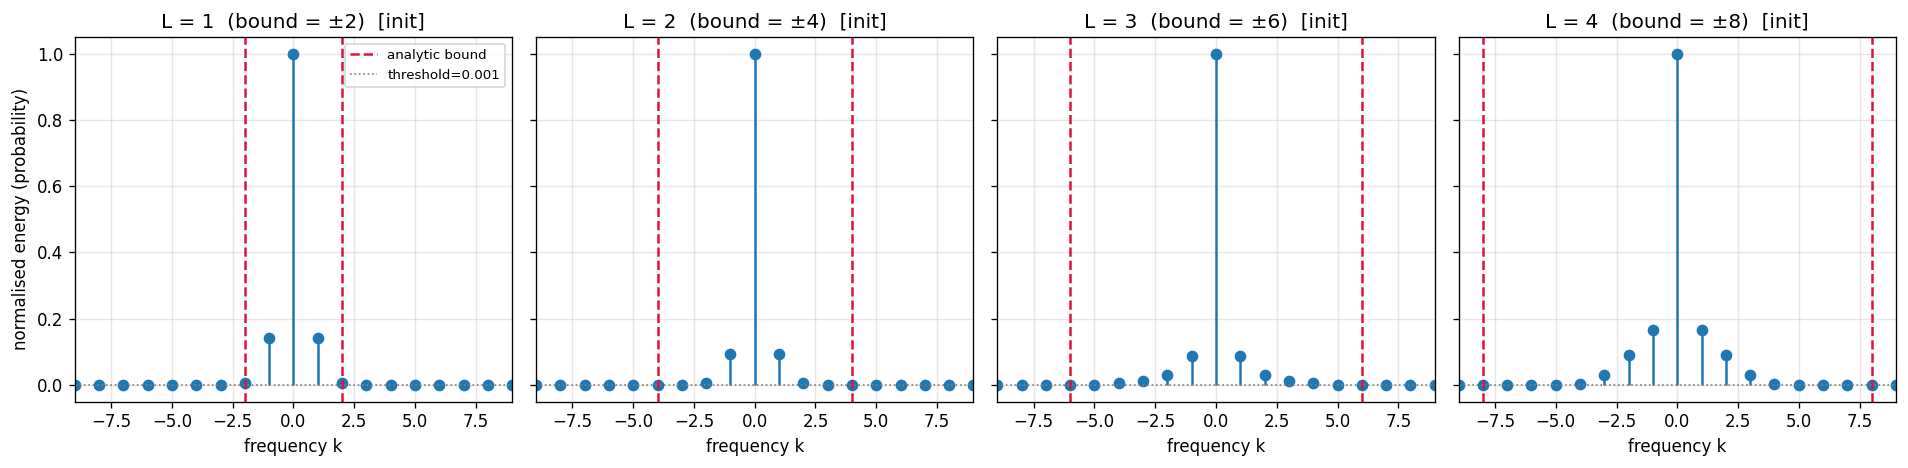

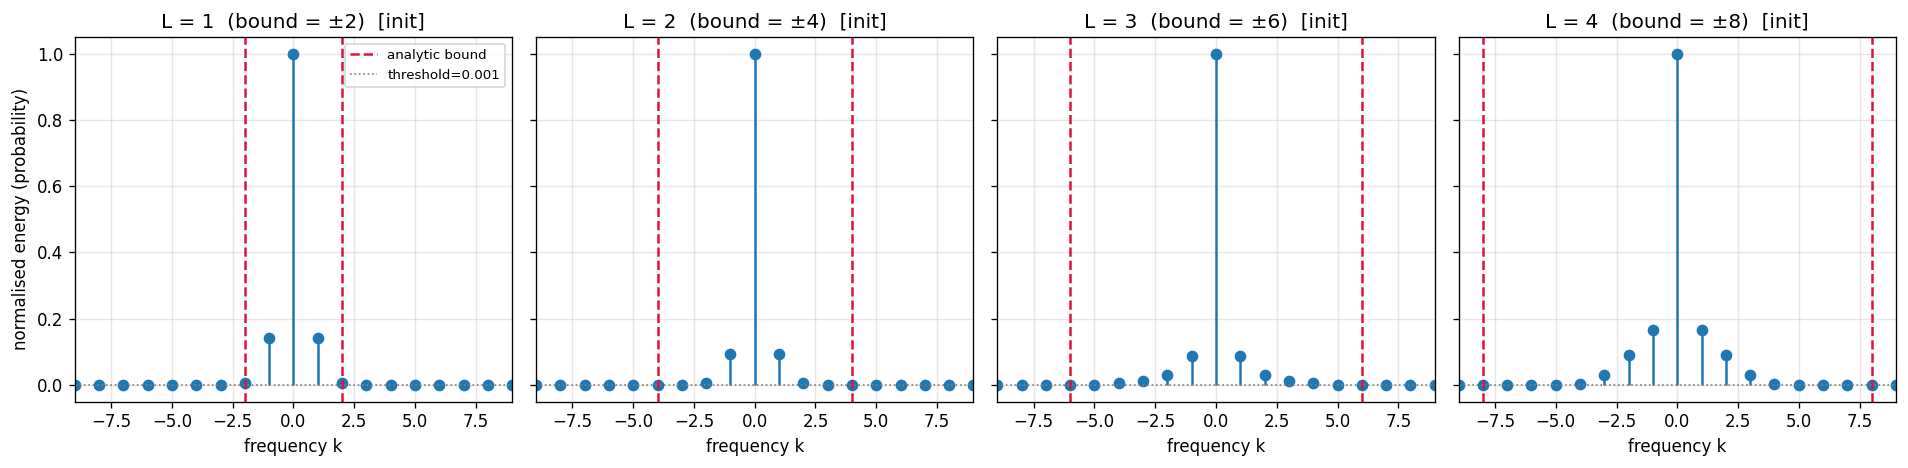

In [29]:
init_results = {}
for L in LAYERS_LIST:
    torch.manual_seed(SEED)
    m = MerlinTunableEntropy(
        feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT,
        n_encoding_layers=L, pde=probe_pde,
    ).to(device)
    init_results[L] = quantum_layer_spectrum(
        m, FEATURE_SIZE, L, feature_index=FEATURE_INDEX, seed=SEED,
        quantity='probability', trained=False,
    )
    eff = effective_bandwidth(init_results[L])
    print(f'L={L}  analytic bound=±{init_results[L].analytic_bound}  '
          f'effective bandwidth=±{eff:.1f}  '
          f'second moment={spectral_second_moment(init_results[L]):.2f}  '
          f'fraction used={fraction_of_ceiling_used(init_results[L]):.2f}')

plot_spectrum_by_layers(init_results, save_path='figures/quantum_spectrum/init_spectrum_by_layers.png')

Saved: figures/quantum_spectrum/bandwidth_vs_layers_init.png


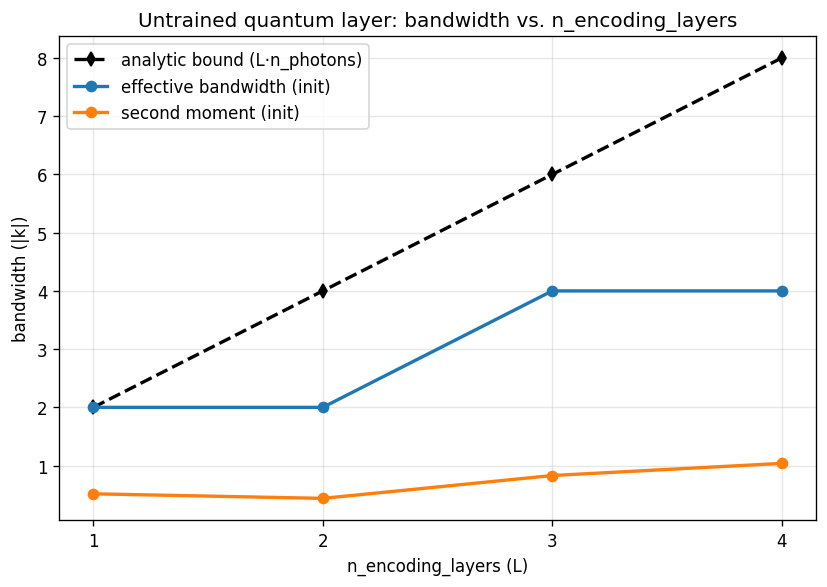

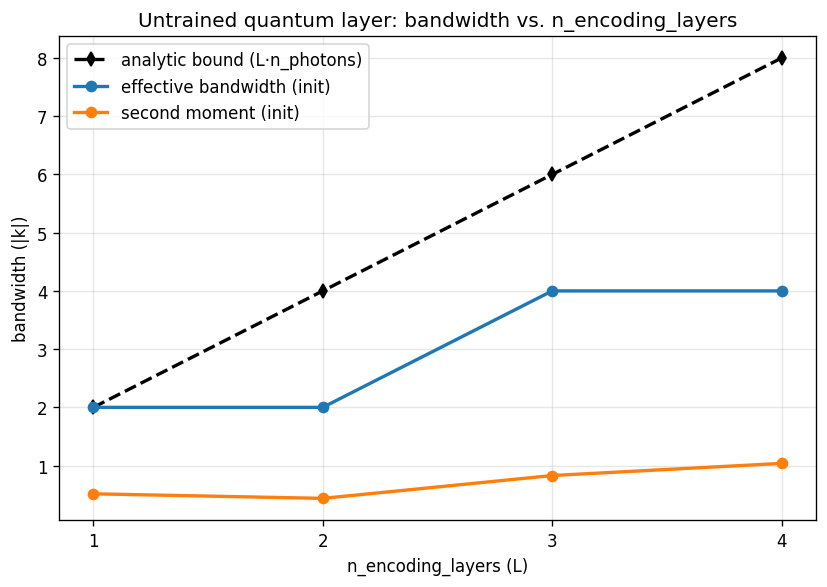

In [30]:
analytic_bounds = [analytic_frequency_bound(FEATURE_SIZE, L) for L in LAYERS_LIST]

plot_bandwidth_vs_layers(
    LAYERS_LIST,
    series={
        'effective bandwidth (init)': [effective_bandwidth(init_results[L]) for L in LAYERS_LIST],
        'second moment (init)': [spectral_second_moment(init_results[L]) for L in LAYERS_LIST],
    },
    analytic_bounds=analytic_bounds,
    title='Untrained quantum layer: bandwidth vs. n_encoding_layers',
    save_path='figures/quantum_spectrum/bandwidth_vs_layers_init.png',
)

## 5 — Analytic bound vs. the learned function (trained)

Train one `MerlinTunableEntropy` per `L` on a **high-frequency**
`WaveEquation` — the regime where the QPINN is reported to pull ahead of
the classical, param-matched baseline — and re-run the *identical*
probability-spectrum sweep on `model.quantum` afterwards. Also keeps the
evaluation grid (`U_pred`, `U_true`) per `L` for Section 6.


Training L=1 encoding layer(s)
Parameters — total: 203  trainable: 203

Training for 800 epochs on cpu  (dtype=torch.float32)
Epoch     1/800 | Loss: 3.9269e+00 | PDE: 3.22e-05 | Cons: 2.13e-01 | IC: 3.82e-01 | BC: 0.00e+00 | Time: 0.0s
Epoch   800/800 | Loss: 2.6353e-01 | PDE: 5.19e-02 | Cons: 3.91e-01 | IC: 1.62e-03 | BC: 0.00e+00 | Time: 29.1s

Done — 29.1s total
Evaluating on 60×60 grid …
  Relative L2 : 5.3705e-01
  MAE         : 1.9792e-01
  Max abs err : 5.8675e-01
  RMSE        : 2.6849e-01
L=1  rel_l2=5.3705e-01  effective bandwidth (trained)=±2.0  fraction used=1.00

Training L=2 encoding layer(s)
Parameters — total: 266  trainable: 266

Training for 800 epochs on cpu  (dtype=torch.float32)
Epoch     1/800 | Loss: 4.8464e+00 | PDE: 4.15e-04 | Cons: 6.80e-03 | IC: 4.84e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch   800/800 | Loss: 1.0380e-01 | PDE: 2.27e-02 | Cons: 1.42e-01 | IC: 9.95e-04 | BC: 0.00e+00 | Time: 42.9s

Done — 42.9s total
Evaluating on 60×60 grid …
  Relative L2 : 2.6

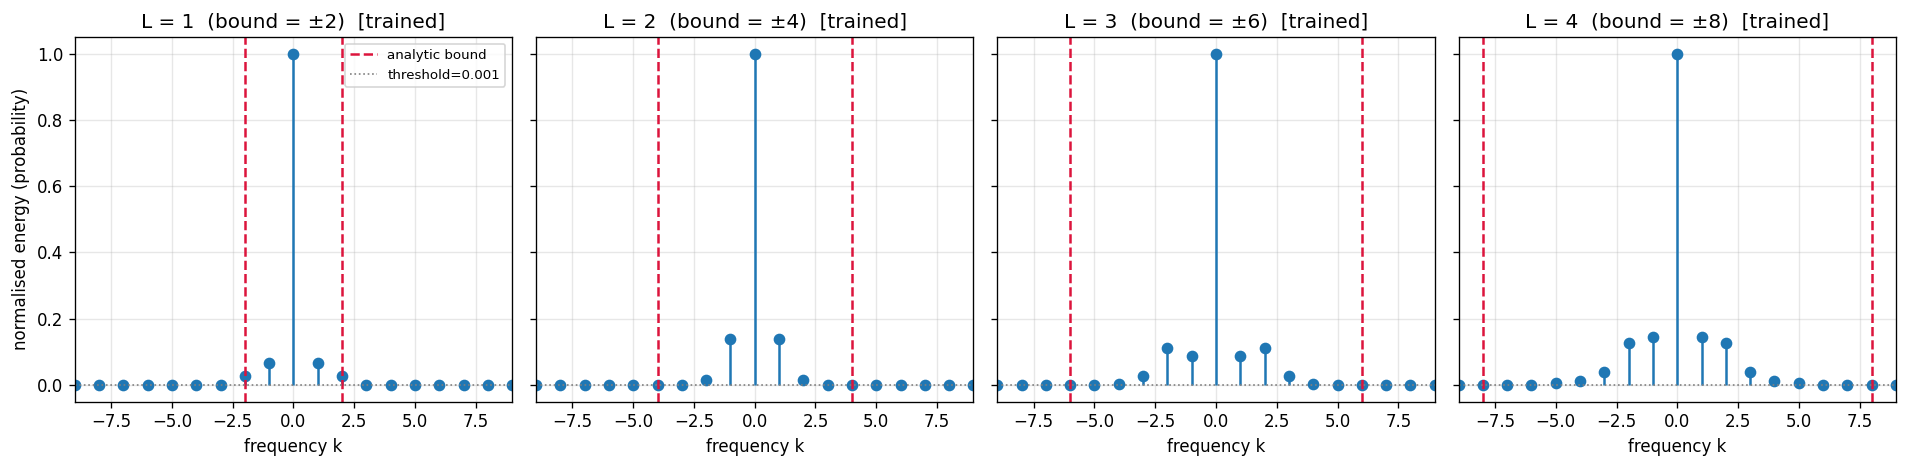

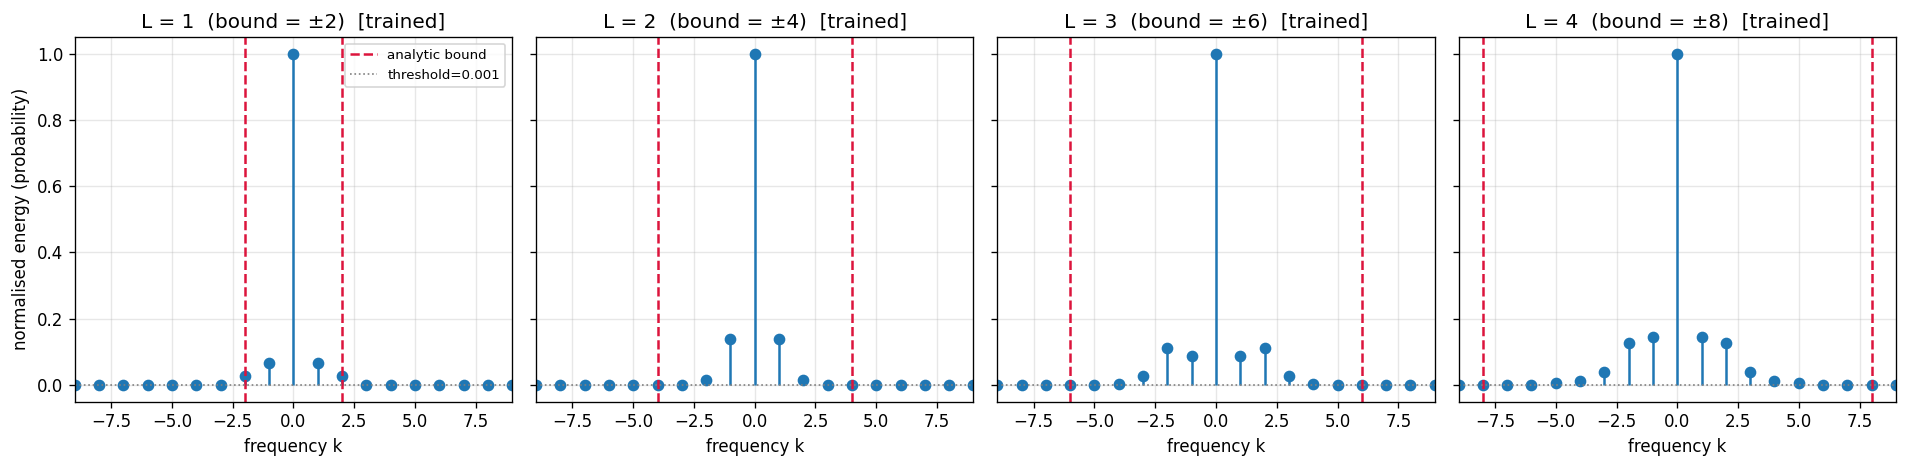

In [34]:
PDE_FREQ = 1.0     # high-frequency regime
TRAIN_EPOCHS = 800

ref_pde = WaveEquation(freq=PDE_FREQ, c=1.0)

trained_results = {}
trained_models = {}
rel_l2_by_layers = {}
U_pred_by_layers = {}
U_true = x_grid = t_grid = None

for L in LAYERS_LIST:
    print(f'\n{"="*60}\nTraining L={L} encoding layer(s)\n{"="*60}')
    torch.manual_seed(SEED)
    m = MerlinTunableEntropy(
        feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT,
        n_encoding_layers=L, pde=ref_pde,
    ).to(device)
    train(model=m, pde=ref_pde, epochs=TRAIN_EPOCHS, seed=SEED, log_every=TRAIN_EPOCHS, device=device, dtype=dtype)

    metrics, U_pred, U_true, x_grid, t_grid = evaluate(model=m, pde=ref_pde, device=device, dtype=dtype)
    rel_l2_by_layers[L] = metrics['rel_l2']
    U_pred_by_layers[L] = U_pred

    trained_models[L] = m
    trained_results[L] = quantum_layer_spectrum(
        m, FEATURE_SIZE, L, feature_index=FEATURE_INDEX, seed=SEED,
        quantity='probability', trained=True,
    )
    print(f'L={L}  rel_l2={metrics["rel_l2"]:.4e}  '
          f'effective bandwidth (trained)=±{effective_bandwidth(trained_results[L]):.1f}  '
          f'fraction used={fraction_of_ceiling_used(trained_results[L]):.2f}')

plot_spectrum_by_layers(trained_results, save_path='figures/quantum_spectrum/trained_spectrum_by_layers.png')

Saved: figures/quantum_spectrum/bandwidth_vs_layers_init_vs_trained.png


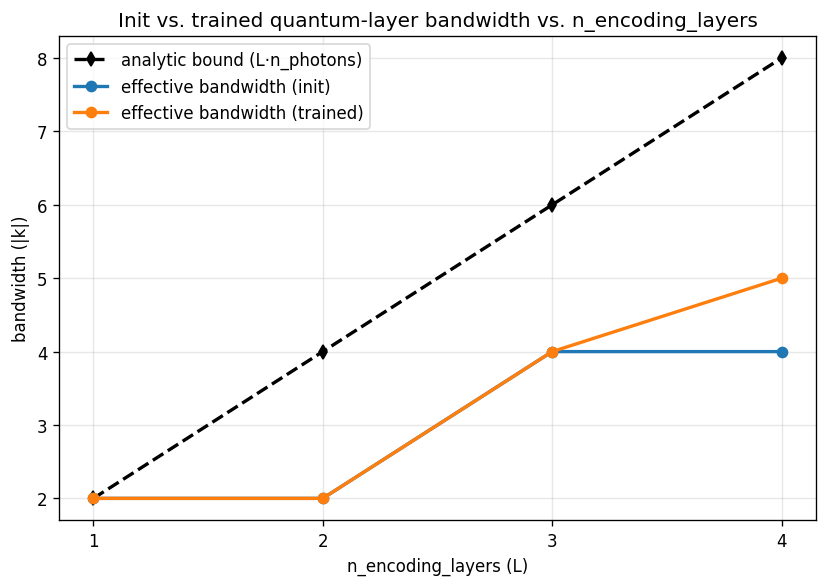

Saved: figures/quantum_spectrum/analytic_vs_effective_gap.png


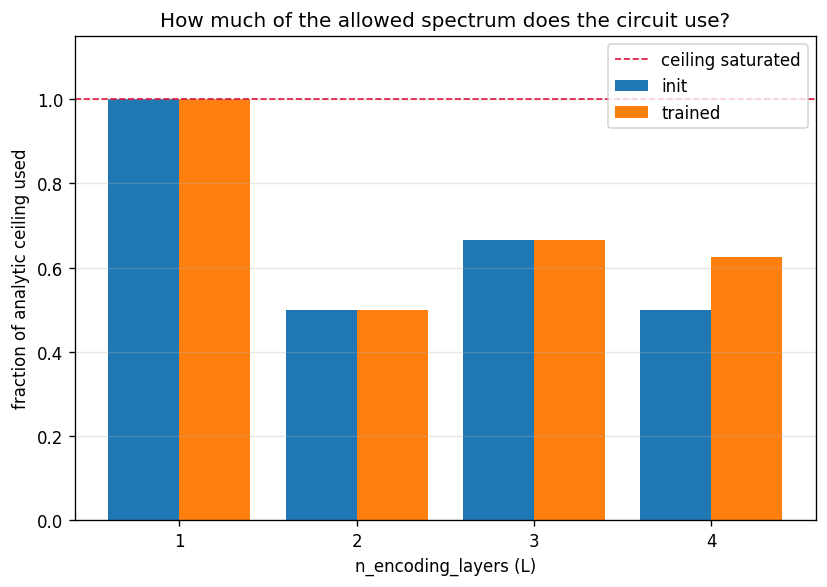

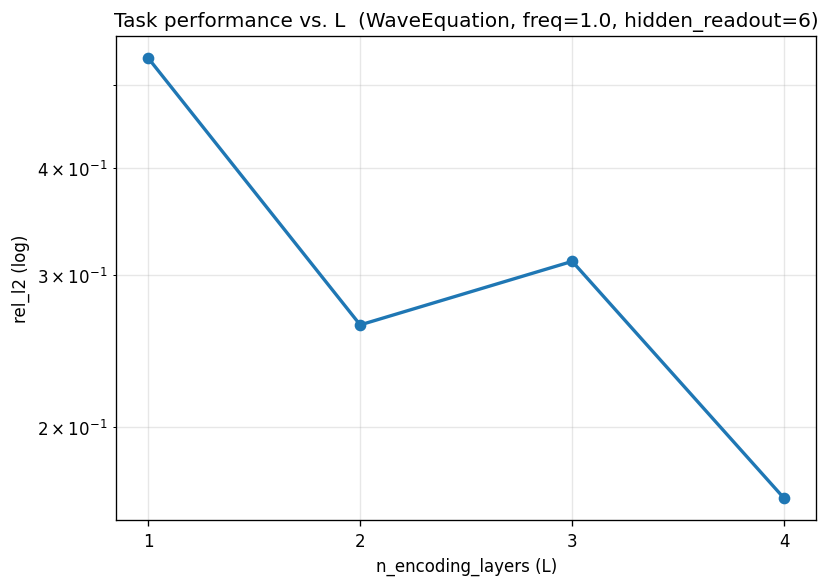

In [35]:
plot_bandwidth_vs_layers(
    LAYERS_LIST,
    series={
        'effective bandwidth (init)': [effective_bandwidth(init_results[L]) for L in LAYERS_LIST],
        'effective bandwidth (trained)': [effective_bandwidth(trained_results[L]) for L in LAYERS_LIST],
    },
    analytic_bounds=analytic_bounds,
    title='Init vs. trained quantum-layer bandwidth vs. n_encoding_layers',
    save_path='figures/quantum_spectrum/bandwidth_vs_layers_init_vs_trained.png',
)

plot_analytic_vs_effective_gap(
    LAYERS_LIST,
    series={
        'init': [fraction_of_ceiling_used(init_results[L]) for L in LAYERS_LIST],
        'trained': [fraction_of_ceiling_used(trained_results[L]) for L in LAYERS_LIST],
    },
    save_path='figures/quantum_spectrum/analytic_vs_effective_gap.png',
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(LAYERS_LIST, [rel_l2_by_layers[L] for L in LAYERS_LIST], marker='o', lw=2)
ax.set_xlabel('n_encoding_layers (L)')
ax.set_ylabel('rel_l2 (log)')
ax.set_title(f'Task performance vs. L  (WaveEquation, freq={PDE_FREQ}, hidden_readout={HIDDEN_READOUT})')
ax.set_xticks(LAYERS_LIST)
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

## 6 — Physical solution spectrum vs. the analytical solution, across L

Sections 4-5 measured the quantum layer's own θ-space spectrum, bypassing
`feature_map`. This is the complementary, physical-space question: for
each trained `L`, how does the model's actual output `u(x, t)`'s Fourier
spectrum compare to the **analytical** PDE solution's spectrum
(`pde.exact_solution`) — and does it visibly gain high-frequency content
as `L` grows, the way Section 5's θ-space bandwidth did?

The dotted vertical line per `L` is a rough, **non-rigorous** reference:
it pushes the θ-space bound `L·n_photons` through the largest observed
`|∂(feature_map slot)/∂x|` (reusing `feature_map_jacobian` from Section 7).
Unlike the θ-space bound itself (Section 2's proof), this is an
order-of-magnitude estimate, not a proven ceiling — the real push-forward
is a chirp (position-dependent, see `physical_bandwidth_note`), and it
collapses every Fock-state coefficient into one slope. Treat it as a
sanity-check reference, not a guarantee.

L=1:  heuristic physical frequency ceiling ≈ 0.6  (θ-space bound was ±2)
L=2:  heuristic physical frequency ceiling ≈ 0.9  (θ-space bound was ±4)
L=3:  heuristic physical frequency ceiling ≈ 1.8  (θ-space bound was ±6)
L=4:  heuristic physical frequency ceiling ≈ 1.3  (θ-space bound was ±8)
Saved: figures/quantum_spectrum/power_spectrum_by_layers.png


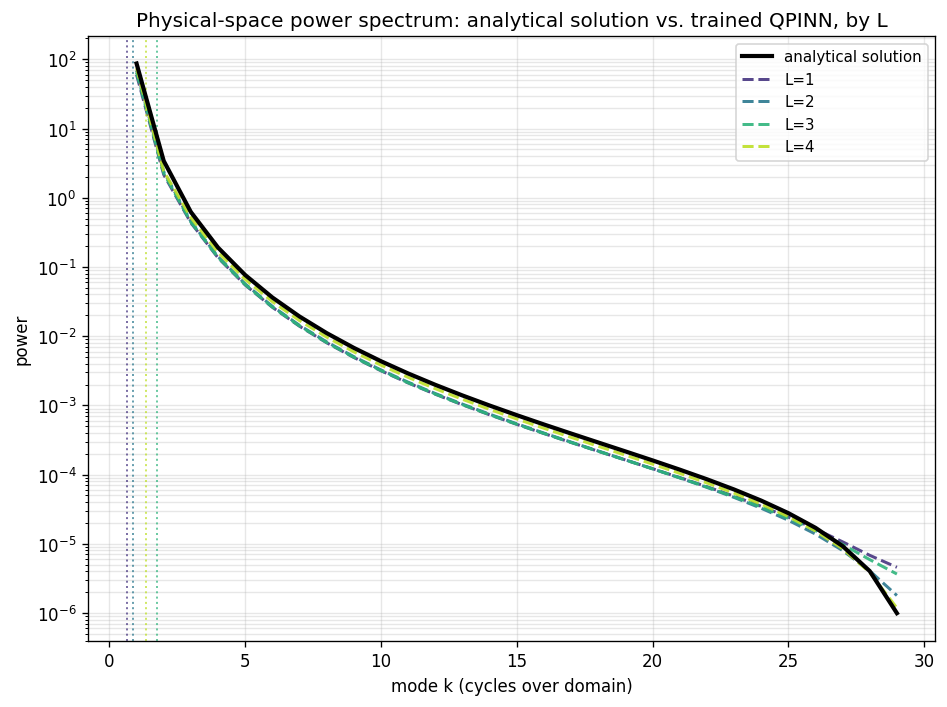

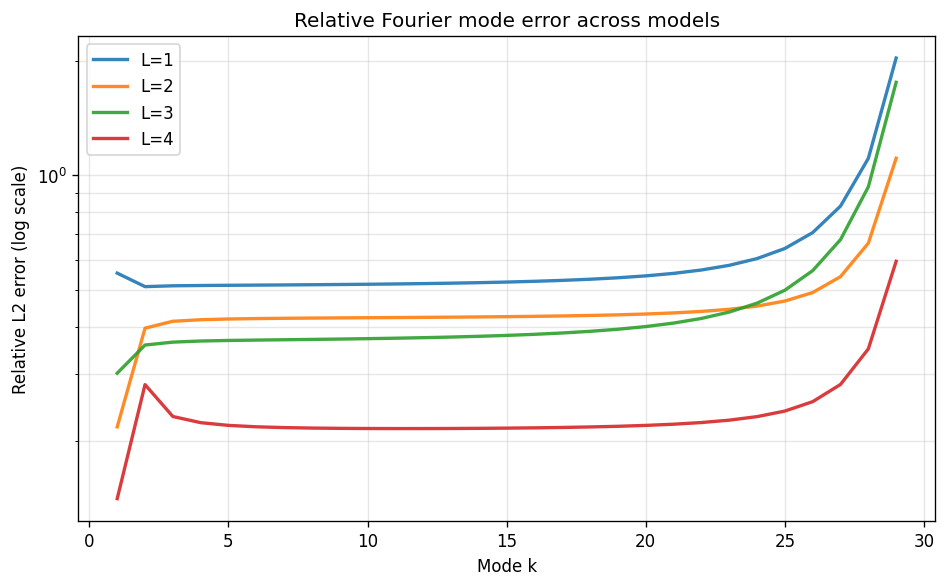

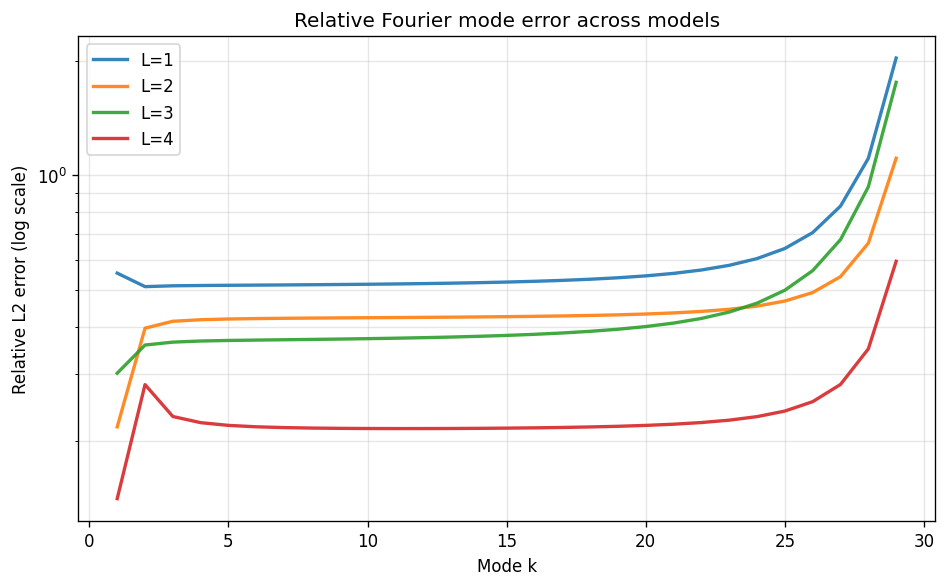

In [36]:
ceiling_sampler = DataSampler(pde=ref_pde, device=device, dtype=dtype)
ceiling_sample_xt = ceiling_sampler.sample_interior(256).detach()

physical_ceiling_by_L = {
    L: estimate_physical_frequency_ceiling(trained_models[L], ceiling_sample_xt, FEATURE_SIZE, L)
    for L in LAYERS_LIST
}
for L in LAYERS_LIST:
    print(f'L={L}:  heuristic physical frequency ceiling ≈ {physical_ceiling_by_L[L]:.1f}  '
          f'(θ-space bound was ±{analytic_frequency_bound(FEATURE_SIZE, L)})')

plot_power_spectrum_by_layers(
    U_true, U_pred_by_layers, LAYERS_LIST,
    physical_ceiling_by_L=physical_ceiling_by_L,
    save_path='figures/quantum_spectrum/power_spectrum_by_layers.png',
)

plot_multi_model_l2_error(
    U_true, [U_pred_by_layers[L] for L in LAYERS_LIST],
    model_names=[f'L={L}' for L in LAYERS_LIST],
    save_path='figures/quantum_spectrum/mode_l2_error_by_layers.png',
)

## 7 — Is `hidden_readout` bottlenecking performance?

If Section 5's bandwidth plot shows the *trained effective bandwidth*
growing with `L` while `rel_l2` (and Section 6's physical spectrum) stay
flat, the quantum layer is making more spectrum available than the model
is actually using to solve the PDE better. One candidate bottleneck:
`hidden_readout`, the width of the `Linear(dimH, hidden_readout) -> Tanh
-> Linear(hidden_readout, 2)` MLP sitting between `q_probs` and
`(u, ux_hat)` — if it's too narrow, it may not be able to route the extra
probability-spectrum content through to the output regardless of how much
bandwidth is available upstream.

This jointly sweeps `(L, hidden_readout)`, retraining a fresh model for
every combination. Read it together with Sections 5-6: if `rel_l2` stays
flat across `hidden_readout_list` even at the `L` with the widest trained
bandwidth, `hidden_readout` is *not* the bottleneck — the flat performance
has to be explained elsewhere (e.g. the encoding/entangling layers not
actually saturating their own ceiling, per Section 5's gap plot, or
something upstream/downstream of the quantum layer entirely). If `rel_l2`
visibly improves with `hidden_readout` specifically at large `L`, the
readout was capping what the extra bandwidth could buy.

`BOTTLENECK_EPOCHS` and the grid sizes below are deliberately modest
(`len(LAYERS_LIST) * len(HIDDEN_READOUT_LIST) * N_SEEDS` full training runs)
— widen once the shape of the result looks informative.

In [ ]:
HIDDEN_READOUT_LIST = [2, 4]
BOTTLENECK_EPOCHS = 800
N_SEEDS = 2

bottleneck_result = run_readout_bottleneck_sweep(
    model_cls=MerlinTunableEntropy,
    feature_size=FEATURE_SIZE,
    pde=ref_pde,
    layers_list=LAYERS_LIST,
    hidden_readout_list=HIDDEN_READOUT_LIST,
    train_fn=train,
    evaluate_fn=evaluate,
    epochs=BOTTLENECK_EPOCHS,
    n_seeds=N_SEEDS,
    seed_base=SEED,
    device=device,
    dtype=dtype,
)

plot_bottleneck_heatmap(bottleneck_result, save_path='figures/quantum_spectrum/bottleneck_heatmap.png')
plot_bottleneck_lines(bottleneck_result, save_path='figures/quantum_spectrum/bottleneck_lines.png')

best_L, best_hr = min(
    bottleneck_result.rel_l2, key=lambda combo: np.mean(bottleneck_result.rel_l2[combo])
)
print(f'\nBest (L, hidden_readout) found: L={best_L}, hidden_readout={best_hr}, '
      f'mean rel_l2={np.mean(bottleneck_result.rel_l2[(best_L, best_hr)]):.4e}')

## 8 — x vs. t mode separation

**Is there anywhere in this pipeline that keeps x-frequency content and
t-frequency content separate? No.** `feature_map` is a single
`Linear(2, hidden_feature) -> Tanh -> Linear(hidden_feature,
total_input_size)` MLP — the very first layer already maps `(x, t)`
through a *shared* hidden layer, so every one of its `total_input_size`
outputs is generically a nonlinear function of *both* `x` and `t`. There is
no output slot that depends on `x` alone or `t` alone. Whatever mixed
scalar comes out is what gets angle-encoded onto a mode; the quantum layer
(and Section 2's bound) only ever sees that mixed scalar and has no notion
of "x-frequency" vs. "t-frequency" to keep apart — the analytic bound
`L·n_photons` is a bound on frequency content in that mixed encoded
variable, not on `k_x` or `k_t` separately.

The cell below makes this concrete: `feature_map_jacobian` computes
`∂(feature_map slot)/∂x` and `∂/∂t` at sampled domain points. A cleanly
x/t-separated architecture would show each slot's cloud sitting on one
axis; expect instead every slot to have non-zero, position-varying
sensitivity to both (the Tanh means even the *degree* of mixing isn't
constant across the domain — see `physical_bandwidth_note` below for how
this also affects turning a `θ`-space frequency into a physical
`(k_x, k_t)`, and Section 6's heuristic ceiling).

In [ ]:
sampler = DataSampler(pde=ref_pde, device=device, dtype=dtype)
sample_xt = sampler.sample_interior(256).detach()

jac = feature_map_jacobian(trained_models[best_L] if best_L in trained_models else trained_models[LAYERS_LIST[-1]], sample_xt)
summary = x_t_mixing_summary(jac)

for j in range(jac.shape[1]):
    print(f'slot {j:2d}:  mean|d/dx|={summary["mean_abs_dx"][j]:.3f}  '
          f'mean|d/dt|={summary["mean_abs_dt"][j]:.3f}  '
          f'ratio(dx/dt)={summary["dx_over_dt_ratio"][j]:.2f}')

plot_x_t_mode_mixing(jac, save_path='figures/quantum_spectrum/x_t_mode_mixing.png')
print(physical_bandwidth_note)

## 9 — Does the extra spectrum actually help solve the PDE?

Using the best `(L, hidden_readout)` combination found in Section 7,
compare against `L=1` at the original `HIDDEN_READOUT` and a classical,
parameter-matched baseline, on the same high-frequency `WaveEquation`.

In [ ]:
torch.manual_seed(SEED)
best_model = MerlinTunableEntropy(
    feature_size=FEATURE_SIZE, hidden_readout=best_hr,
    n_encoding_layers=best_L, pde=ref_pde,
).to(device)
train(model=best_model, pde=ref_pde, epochs=BOTTLENECK_EPOCHS, seed=SEED, log_every=BOTTLENECK_EPOCHS, device=device, dtype=dtype)
metrics_best, U_pred_best, U_true, x_grid, t_grid = evaluate(model=best_model, pde=ref_pde, device=device, dtype=dtype)

QUANTUM_OUTPUT_SIZE = int(quantum_outputsize_for_param_match(FEATURE_SIZE, HIDDEN_READOUT))
torch.manual_seed(SEED)
classical_model = ClassicalHeatQPINN(
    feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT,
    quantum_output_size=QUANTUM_OUTPUT_SIZE, pde=ref_pde,
).to(device)
train(model=classical_model, pde=ref_pde, epochs=BOTTLENECK_EPOCHS, seed=SEED, log_every=BOTTLENECK_EPOCHS, device=device, dtype=dtype)
metrics_c, U_pred_c, _, _, _ = evaluate(model=classical_model, pde=ref_pde, device=device, dtype=dtype)

_, U_pred_q1, _, _, _ = evaluate(model=trained_models[1], pde=ref_pde, device=device, dtype=dtype)

q_params = sum(p.numel() for p in best_model.parameters())
c_params = sum(p.numel() for p in classical_model.parameters())
print(f'quantum (L={best_L}, hidden_readout={best_hr}) params: {q_params}   classical (param-matched) params: {c_params}')
print(f'rel_l2 — classical: {metrics_c["rel_l2"]:.4e} | '
      f'QPINN L=1,hr={HIDDEN_READOUT}: {rel_l2_by_layers[1]:.4e} | '
      f'QPINN L={best_L},hr={best_hr}: {metrics_best["rel_l2"]:.4e}')

plot_multi_model_l2_error(
    U_true, [U_pred_q1, U_pred_best, U_pred_c],
    model_names=[f'QPINN L=1', f'QPINN L={best_L},hr={best_hr}', 'Classical (param-matched)'],
    save_path='figures/quantum_spectrum/task_l2_error_by_model.png',
)

## 10 — Summary

Fill in from the run above:

- **Proof (Section 2):** the bound is `±L·n_photons` on the *probability*
  spectrum specifically — note if your earlier reading of this notebook
  used the raw amplitude, that was one-sided, not symmetric.
- **Architecture (Section 4):** effective bandwidth at init tracked / did
  not track the ceiling — state the observed `fraction_of_ceiling_used`
  values.
- **Learned function (Section 5):** training moved the effective bandwidth
  \[toward / away from / not appreciably\] the ceiling; rel_l2 was flat vs.
  `L` \[despite / consistent with\] bandwidth growth.
- **Physical spectrum (Section 6):** the predicted solution's power
  spectrum \[did / did not\] visibly gain high-`k` content as `L` grew, and
  \[did / did not\] approach the heuristic physical ceiling.
- **Readout bottleneck (Section 7):** rel_l2 \[did / did not\] improve with
  `hidden_readout` at the `L` with the widest bandwidth — state whether
  `hidden_readout` is implicated, and what the best `(L, hidden_readout)`
  combo was.
- **x/t separation (Section 8):** confirmed no architectural separation
  between spatial and temporal frequency content anywhere in the pipeline;
  the analytic bound is on the encoded scalar's frequency, not on `k_x` or
  `k_t` individually.
- **Task performance (Section 9):** the best `(L, hidden_readout)` combo
  beat `L=1` and the classical, parameter-matched baseline by \[margin\].